In [1]:
from matplotlib import pyplot as plt
import os
import sys
import numpy as np
import pandas as pd
import cv2

model_data = {
    'tasks': ['Flattening'],
    'method': 'diffusion',
    'fabrics': ['A'],
    'heatmap': False,
    'input_obs_rgb': False,
    'input_obs_depth': False,
    'denoise_obs': False,
    'grasp_img': False,
    'exp_dirs': [
        'flattening-agent-cloth-mask-centre-multiple-prioritise-middle+RGB2M-on-mix-800k-all-garment-bonus-penalty-v2-50000'
        #'flattening-agent-cloth-mask-centre-multiple-prioritise-middle+RGB2M-on-mix-200k-sf-50000',
    ]
}
model = model_data
exp_dirs = model['exp_dirs']
tasks = model['tasks']
# method = model['method']
  
fabrics = model['fabrics']
heatmap = model['heatmap']
input_obs_rgb = model['input_obs_rgb']
input_obs_depth = model.get('input_obs_depth', False)
denoise_obs = model.get('denoise_obs', False)
grasp_img = model.get('grasp_img', False)

In [2]:
## get all direcotry not recursive in the current directory
def get_all_dir(path):
    print(path)
    ret = []
    for d in os.listdir(path):
        
        dir_path = os.path.join(path, d)
        if os.path.isdir(dir_path):
            ret.append(dir_path)

    return ret

# for exp_dir in exp_dirs:
#     experiments = get_all_dir(exp_dir)
#     experiments = sorted(experiments)
import json

def coverage_alignment_reward(NC1, NC2, IoU1, IoU2):
    dNC = NC2 - NC1
    du = IoU2 - IoU1
    alpha = 2
    beta = 1
    rca = max(np.tanh(alpha*dNC + du*beta), 0)
    b = 0.7

    if NC1 > 0.9 and NC2 < 0.9:
        return 0
    
    if NC2 >= 0.95:
        return b
    
    return rca


print_reward = True
OBJECT = 'garment'

In [3]:
## show action_images as a trajecotry in an experiment

def show_trajectory(experiment, plt_steps=None, task='Flattening'):
    print('experiment:', experiment)
    ## get all steps in the experiment, they are folders
    steps = [d for d in os.listdir('./' + experiment) if os.path.isdir('./' + experiment + '/' + d)]
    #print('steps:', steps)
    steps = [int(s.split('_')[-1]) for s in steps if 'step' in s]
    plt_steps = steps if plt_steps is None else plt_steps
    plt_steps = sorted(plt_steps)
    horizon = len(plt_steps)
    #print('horizon:', horizon)
   


    action_images = []
    rgb_images = []
    pick_heat_images = []
    place_heat_images = []
    mask_images = []
    depth_images = []
    input_obs_images = []
    input_obs_d_images = []
    normalised_coverages = []
    grasp_imgs = []
    denoise_obs_imgs = []
    IoUs = []
    print('plt_steps:', plt_steps)

    for i in plt_steps:
        print('step', i)
        rgb_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/workspace_rgb.png'))
        mask_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/mask.png'))
        depth_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/depth.png'))

        # it is in evaluation.json file
        
        with open(experiment + '/' + f'step_{str(i)}' + '/evaluation.json') as f:
            eval = json.load(f)
            if task == 'Flattening':
                normalised_coverages.append(eval['normalised_coverage'])
                IoUs.append(eval['max_IoU'])

        with open(experiment  + '/info.json') as f:
            info = json.load(f)
            posterior_rewards = info['posterior_rewards']
            prior_rewards = info['prior_rewards']
        
        
        if i != plt_steps[-1]:
            if input_obs_rgb:
                input_obs_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/input_obs_rgb.png'))
            
            if input_obs_depth:
                input_obs_d_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/input_obs_depth.png'))

            if denoise_obs:
                denoise_obs_imgs.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/noise_actions_obs_depth.png'))
            
            if grasp_img:
                grasp_imgs.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/grasp_image.png'))

            #action_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/action_obs_rgb.png'))
            action_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/action_image.png'))
            if heatmap:
                pick_heat_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/pick-heat.png'))
                place_heat_images.append(plt.imread(experiment + '/' + f'step_{str(i)}' + '/place-heat.png'))
    
    row = 6 if heatmap else 4
    if input_obs_rgb:
        row += 1
    if input_obs_depth:
        row += 1
    if denoise_obs:
        row += 1
    if grasp_img:
        row += 1
    depth_list = []
    for i, depth in enumerate(input_obs_d_images):
        d = cv2.applyColorMap(np.uint8(255 * depth), cv2.COLORMAP_JET)
        d = cv2.cvtColor(d, cv2.COLOR_BGR2RGB)
        depth_list.append(d)
    input_obs_d_images = depth_list

    plt_horizon = max(10, horizon)
    plt_horizon = horizon #min(plt_horizon, 20)
    fig, axs = plt.subplots(row, horizon, figsize=(plt_horizon*4, (4)*row))
    for i in range(horizon):
        axs[0, i].imshow(rgb_images[i])
        axs[1, i].imshow(mask_images[i])
       

        axs[2, i].imshow(1.0-depth_images[i], cmap='cividis')
        
        if i < horizon-1:
            axs[-1, i].imshow(action_images[i])
            b = 0

            
            
            if grasp_img:
               
                axs[-2-b, i].imshow(grasp_imgs[i])
                b += 1
            
            if denoise_obs:
                
                axs[-2-b, i].imshow(denoise_obs_imgs[i])
                b += 1

            if input_obs_rgb:
                axs[-2-b, i].imshow(input_obs_images[i])
                b += 1
            if input_obs_depth:
                #axs[-2-b, i].imshow(input_obs_d_images[i])
                ## colormap fancy
                axs[-2-b, i].imshow(input_obs_d_images[i], cmap='cividis')
                b += 1
            
            

            if heatmap:
                axs[-2-b, i].imshow(pick_heat_images[i])
                axs[-3-b, i].imshow(place_heat_images[i])
        else:
            axs[-1, i].imshow(rgb_images[-1])
        
        
        axs[0, i].axis('off')
        axs[1, i].axis('off')
        axs[2, i].axis('off')
        axs[-1, i].axis('off')
        b = 0
        print('denoise_obs:', denoise_obs)
        if grasp_img:
            axs[-2-b, i].axis('off')
            b +=1
        if denoise_obs:
            axs[-2-b, i].axis('off')
            b +=1
        

        if input_obs_rgb:
            axs[-2-b, i].axis('off')
            b +=1   
        if input_obs_depth:
            axs[-2-b, i].axis('off')
            b +=1
       

        if heatmap:
            axs[-2-b, i].axis('off')
            axs[-3-b, i].axis('off')
    
    # Add text on the first image of each row
    label_fontsize = 18
    label_color = 'white'  # Change to white for better visibility on dark images
    label_bgcolor = 'black'  # Background color for contrast
    label_alpha = 0.7
    label_pad = 5

    def add_text(ax, text, pos='bottom'):
        if pos == 'bottom':
            ax.text(0.5, 0.05, text, fontsize=label_fontsize, color=label_color,
                    transform=ax.transAxes, va='bottom', ha='center',
                    bbox=dict(facecolor=label_bgcolor, alpha=label_alpha, edgecolor='none', pad=label_pad))
        else:
            ax.text(0.5, 0.95, text, fontsize=label_fontsize, color=label_color,
                    transform=ax.transAxes, va='top', ha='center',
                    bbox=dict(facecolor=label_bgcolor, alpha=label_alpha, edgecolor='none', pad=label_pad))

    add_text(axs[0, 0], 'RGB')
    add_text(axs[1, 0], 'Mask')
    add_text(axs[2, 0], 'Depth')
    #add_text(axs[-1, 0], 'Action on Input RGB')
    for i in range(horizon):
        if task == 'Flattening':
            string2print = f'NC: {int(normalised_coverages[i]*100)}'
            if OBJECT == 'garment':
                string2print += f', IoU: {int(IoUs[i]*100)}'
            
            if print_reward == True and i > 0 and i < horizon:
                reward = coverage_alignment_reward(
                    normalised_coverages[i-1], 
                    normalised_coverages[i],
                    IoUs[i-1],
                    IoUs[i])
                string2print += f'\n GT-R: {int(reward*100)}, PST-R: {int(posterior_rewards[i]*100)}, PR-R: {int(prior_rewards[i-1]*100)},'

            add_text(axs[-1, i], string2print, pos='bottom')
        else:
            add_text(axs[-1, i], f'IoU: {IoUs[i]:.2f}', pos='bottom')
    

    b = 0

    
    if grasp_img:
        add_text(axs[-2-b, 0], 'Grasping')
        b +=1

    if denoise_obs:
        add_text(axs[-2-b, 0], 'Denoising')
        b +=1

    if input_obs_rgb:
        add_text(axs[-2-b, 0], 'Input RGB')
        
        b +=1
    if input_obs_depth:
        add_text(axs[-2-b, 0], 'Input Depth')
        b +=1
   
    if heatmap:
        add_text(axs[-2-b, 0], 'Pick Heat')
        add_text(axs[-3-b, 0], 'Place Heat')
        
    
    ## remove the inter-space between subplots
    #plt.subplots_adjust(wspace=0, hspace=0)
    fig.subplots_adjust(left=0, right=1, top=1, bottom=0, wspace=0, hspace=0)
    fig.tight_layout(pad=0)

    # make it tight, column inter-space is 0
    #plt.tight_layout()
    plt.savefig(experiment + '/trajectory.png')
    plt.show()



In [4]:
## Get step-wise evaluation results
import json
def get_stepwise_eval(experiment):
    steps = [d for d in os.listdir('./' + experiment) if os.path.isdir('./' + experiment + '/' + d)]
    ## filter the steps that have `goal` in the name
    steps = [s for s in steps if 'step' in s]
    #print('steps:', steps)
    horizon = len(steps)
    #print('horizon:', horizon)
    evaluations = {
        'trial': [],
        'fabric': [],
        'state': [],
    }
    
    for i in range(horizon):
        eval_file = experiment + '/' + f'step_{str(i)}' + '/evaluation.json'
        if not os.path.exists(eval_file):
            print('evaluation file not found:', eval_file)
            continue
        evaluations['fabric'].append(experiment.split('/')[-1].split('-')[0])
        evaluations['trial'].append(experiment.split('/')[-1].split('-')[-1])
        evaluations['state'].append(i)
        with open(eval_file, 'r') as f:
            eval_data = json.load(f)
            for k, v in eval_data.items():
                if k not in evaluations:
                    evaluations[k] = []
                evaluations[k].append(v)
    df = pd.DataFrame(evaluations)
    df['steps'] = horizon - 1
    return df

totoal_stats_IoU = []
total_human_success = []
total_stats_nc = []
total_stats_ni = []
for task, exps in zip(tasks, exp_dirs):
    print('############################################\n\n')
    print(task)
    experiments = get_all_dir(exps)
    evals = []
    for exp in experiments:
        evals.append(get_stepwise_eval(exp))

    eval_df = pd.concat(evals)

    if 'IoU' in eval_df.columns:
        # IoU x 100
        eval_df['IoU'] = eval_df['IoU'] * 100
        #display(eval_df)

        # for each fabric trial, get the largest IoU

        IoU_stats_df = eval_df.groupby(['fabric', 'trial']).agg({'IoU': 'max'}).reset_index()
        totoal_stats_IoU.append(IoU_stats_df)
        # for each fabric print the mena and std of IoU from IoU_stats_df
        IoU_stats_df = IoU_stats_df.groupby('fabric').agg({'IoU': ['mean', 'std']}).reset_index()
        for fabric in fabrics:
            print(fabric)
            #print mean and std of IoU
            display(IoU_stats_df[IoU_stats_df['fabric'] == fabric])
            print()
    
    if 'normalised_coverage' in eval_df.columns:
        eval_df['normalised_coverage'] = eval_df['normalised_coverage'] * 100
        # get the row for the last state for eah fabric trial, and get the mean and std of normalised_coverage for each fabric
        nc_stats_df = eval_df[eval_df['normalised_coverage'] < 101.0]
        nc_stats_df = nc_stats_df.groupby(['fabric', 'trial']).agg({'normalised_coverage': 'max'}).reset_index()
        total_stats_nc.append(nc_stats_df)
        nc_stats_df = nc_stats_df.groupby('fabric').agg({'normalised_coverage': ['mean', 'std']}).reset_index()

       
        for fabric in fabrics:
            print(fabric)
            display(nc_stats_df[nc_stats_df['fabric'] == fabric])
            print()

    if 'normalised_improvement' in eval_df.columns:
        eval_df['normalised_improvement'] = eval_df['normalised_improvement'] * 100
        ni_stats_df = eval_df[eval_df['normalised_improvement'] < 101.0]
        ni_stats_df = ni_stats_df.groupby(['fabric', 'trial']).agg({'normalised_improvement': 'max'}).reset_index()
        total_stats_ni.append(ni_stats_df)
        ni_stats_df = ni_stats_df.groupby('fabric').agg({'normalised_improvement': ['mean', 'std']}).reset_index()

        for fabric in fabrics:
            print(fabric)
            display(ni_stats_df[ni_stats_df['fabric'] == fabric])

    ## display steps statistics mean and std
    print('Steps statistics')
    display(eval_df.groupby('fabric').agg({'steps': ['mean', 'std']}))
    ## total statistics for steps
    print('Total steps statistics')
    display(eval_df.agg({'steps': ['mean', 'std']}))
    # get the largest 'state' for each fabric trial
    human_success_df = eval_df.groupby(['fabric', 'trial']).agg({'human success': 'max'}).reset_index()
    # count the number of True for each fabric
    human_success_df = human_success_df.groupby('fabric').agg({'human success': 'sum'}).reset_index()

    #display(human_success_df)
    # get the number of trials for each fabric
    num_trials_df = eval_df.groupby('fabric').agg({'trial': 'nunique'}).reset_index()

    # combine the two dataframes
    human_success_df = human_success_df.merge(num_trials_df, on='fabric')
    human_success_df.columns = ['fabric', 'num_human_success', 'num_trials']
    total_human_success.append(human_success_df)
    display(human_success_df)


## get total stats


if len(total_stats_nc) > 0:
    total_stats_nc = pd.concat(total_stats_nc)
    print('\n\nTotal normalised coverage stats')
    display(total_stats_nc.agg({'normalised_coverage': ['mean', 'std']}))

if len(total_stats_ni) > 0:
    total_stats_ni = pd.concat(total_stats_ni)
    print('\n\nTotal normalised improvement stats')
    display(total_stats_ni.agg({'normalised_improvement': ['mean', 'std']}))

if len(totoal_stats_IoU) > 0:
    totoal_stats_IoU = pd.concat(totoal_stats_IoU)
    print('\n\nTotal IoU stats')
    display(totoal_stats_IoU.agg({'IoU': ['mean', 'std']}))

total_human_success = pd.concat(total_human_success)
print('\n\nTotal human success')
display(total_human_success.agg({'num_human_success': 'sum', 'num_trials': 'sum'}))


############################################


Flattening
flattening-agent-cloth-mask-centre-multiple-prioritise-middle+RGB2M-on-mix-800k-all-garment-bonus-penalty-v2-50000
A


Empty DataFrame
Columns: [(fabric, ), (normalised_coverage, mean), (normalised_coverage, std)]
Index: []


A


Empty DataFrame
Columns: [(fabric, ), (normalised_improvement, mean), (normalised_improvement, std)]
Index: []

Steps statistics


steps     
        mean  std
fabric           
dress    6.0  0.0

... (5 outputs left out)



Total normalised improvement stats


,normalised_improvement
mean,33.265483
std,NaN




Total human success


num_human_success    0
num_trials           1
dtype: int64

############################################


Flattening
flattening-agent-cloth-mask-centre-multiple-prioritise-middle+RGB2M-on-mix-800k-all-garment-bonus-penalty-v2-50000
experiment: flattening-agent-cloth-mask-centre-multiple-prioritise-middle+RGB2M-on-mix-800k-all-garment-bonus-penalty-v2-50000/dress-0
plt_steps: [0, 1, 2, 3, 4, 5, 6]
step 0
step 1
step 2
step 3
step 4
step 5
step 6
denoise_obs: False
denoise_obs: False
denoise_obs: False
denoise_obs: False
denoise_obs: False
denoise_obs: False
denoise_obs: False


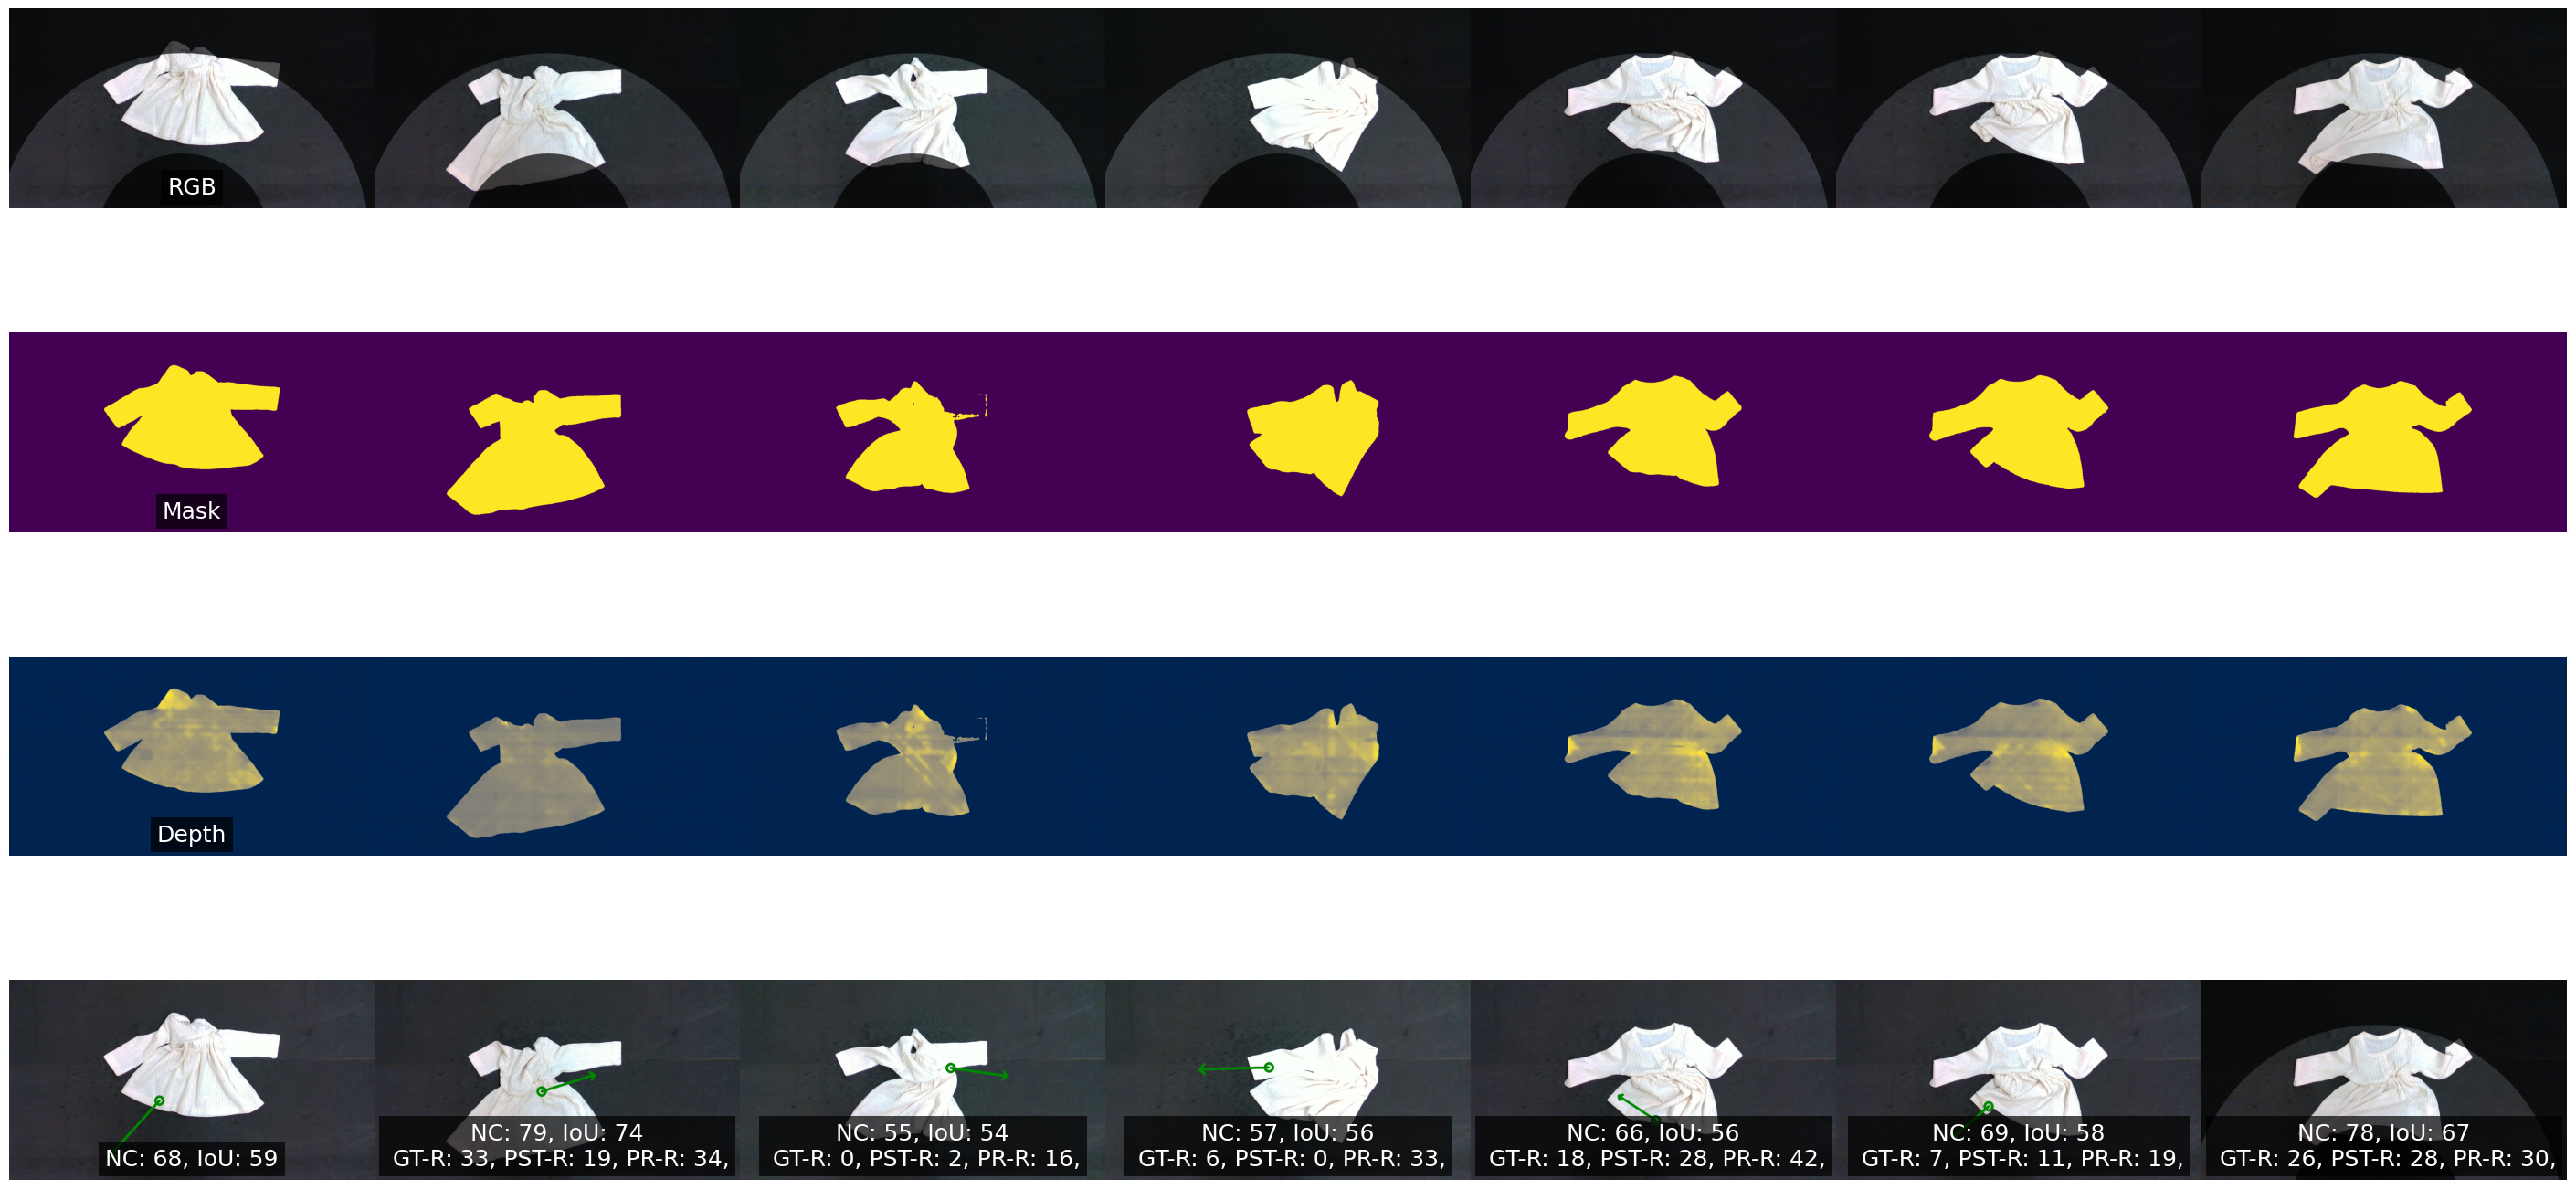

In [5]:

for task, exps in zip(tasks, exp_dirs):
    print('############################################\n\n')
    print(task)
    experiments = get_all_dir(exps)

    for exp in experiments:
        show_trajectory(exp, task=task)#, plt_steps=[0, 1, 2, 3, 5, 6, 7])


In [6]:
from fpdf import FPDF
import pandas as pd
import csv
import io

pdf = FPDF()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.set_font("Arial", size=12)

for task, exps in zip(tasks, exp_dirs):
    print('############################################\n\n')
    print(task)
    experiments = get_all_dir(exps)

    for i, exp in enumerate(experiments):
        pdf.add_page()
        # add text of exp
        text = exp.split('/')[-1]
        pdf.cell(200, 10, txt=text, ln=True, align='C')
        # let the image fit the page, considering both width and height
        pdf.image(exp + '/trajectory.png', x=10, y=20, w=190)

        ## add evaluation results
        pdf.add_page()
        pdf.cell(200, 10, txt='Evaluation', ln=True, align='C')
        
        # Convert DataFrame to CSV string
        csv_buffer = io.StringIO()
        # get rid of fabric and trial columns
        eval_df = get_stepwise_eval(exp)
        eval_df = eval_df.drop(columns=['fabric', 'trial'])
        eval_df.to_csv(csv_buffer, index=False)
        csv_string = csv_buffer.getvalue()
        
        # Parse CSV string
        csv_reader = csv.reader(csv_string.splitlines())
        
        # Set a smaller font size for the table
        pdf.set_font("Arial", size=10)
        
        # Calculate column widths and overall table width
        data = list(csv_reader)
        col_widths = [max(len(str(row[i])) for row in data) * 2.5 for i in range(len(data[0]))]
        ## add the first column width
        #col_widths.insert(0, 5)
        table_width = sum(col_widths)
        
        # Scale column widths if table is too wide
        page_width = pdf.w - 20  # Assuming 10mm margin on each side
        if table_width > page_width:
            scale = page_width / table_width
            col_widths = [w * scale for w in col_widths]
        
        # Print CSV data
        for j, row in enumerate(data):
            pdf.ln(10)  # Add some vertical space between rows
            #pdf.cell(col_widths[0], 10, str(j-1), border=1, align='C')
            for i, col in enumerate(row):
                # if it can be converted to float, then print it with 2 decimal points
                if col.replace('.', '', 1).isdigit():
                    val = float(col)
                    pdf.cell(col_widths[i], 10, f"{val:.2f}", border=1, align='C')
                else:
                    pdf.cell(col_widths[i], 10, str(col), border=1, align='C')
        
        # Reset font size
        pdf.set_font("Arial", size=12)

    pdf.output(f"files/{exps}.pdf")


ModuleNotFoundError: No module named 'fpdf'